1. Which era had the highest global video game sales, and how did sales change over the years?

2. Which video game genres generated the highest global sales, and how do genre preferences differ across regions?

3. Which gaming platforms achieved the highest global sales, and how did their popularity change over time?

In [1]:
import pandas as pd
df = pd.read_csv('vgsales.csv')

In [2]:
df['Year'].min(), df['Year'].max()

(1980.0, 2020.0)

Note: All sales figures (NA, EU, JP, Other and Global) are measured in millions of video game copies sold, not revenue.

In [3]:
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [4]:
df.isnull().sum()

,0
Rank,0
Name,0
Platform,0
Year,271
Genre,0
Publisher,58
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0


In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.dtypes

,0
Rank,int64
Name,object
Platform,object
Year,float64
Genre,object
Publisher,object
NA_Sales,float64
EU_Sales,float64
JP_Sales,float64
Other_Sales,float64


In [7]:
df.shape

(16598, 11)

In [8]:
yearly_sales = df.groupby('Year')['Global_Sales'].sum()
yearly_sales

,Global_Sales
Year,
1980.0,11.38
1981.0,35.77
1982.0,28.86
1983.0,16.79
1984.0,50.36
1985.0,53.94
1986.0,37.07
1987.0,21.74
1988.0,47.22


In [9]:
yearly_sales.sort_values(ascending=False)

,Global_Sales
Year,
2008.0,678.90
2009.0,667.30
2007.0,611.13
2010.0,600.45
2006.0,521.04
2011.0,515.99
2005.0,459.94
2004.0,419.31
2002.0,395.52


In [10]:
df.groupby((df['Year'] // 10) * 10)['Global_Sales'].sum().sort_values(ascending=False)

,Global_Sales
Year,
2000.0,4644.02
2010.0,2520.56
1990.0,1278.91
1980.0,376.58
2020.0,0.29


<Axes: xlabel='Year'>

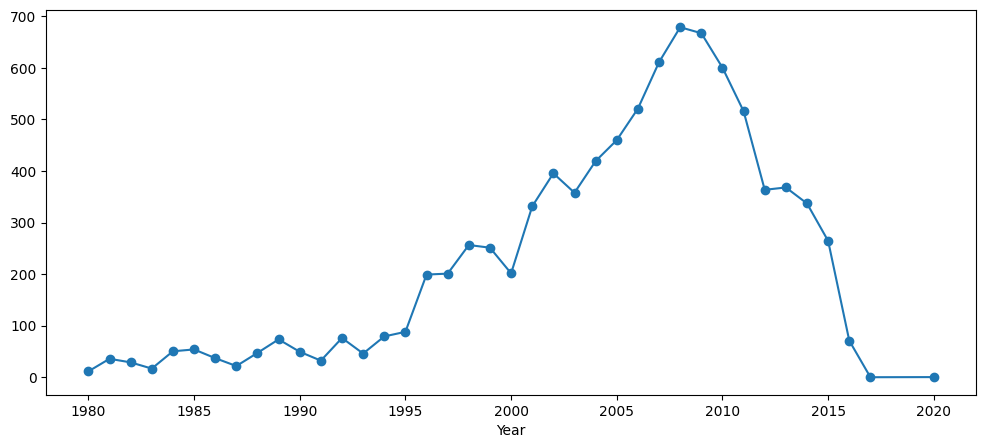

In [11]:
yearly_sales.plot(kind = 'line', figsize = (12, 5), marker = 'o')

Question 1:

The 2000s recorded the highest global video game sales, with approximately 4.64 billion copies sold. Annual sales peaked in 2008 at 678.90 million copies, followed by a general decline after 2009.

In [12]:
genre_sales = df.groupby('Genre')['Global_Sales'].sum()
genre_sales.sort_values(ascending=False)

,Global_Sales
Genre,
Action,1751.18
Sports,1330.93
Shooter,1037.37
Role-Playing,927.37
Platform,831.37
Misc,809.96
Racing,732.04
Fighting,448.91
Simulation,392.20


In [13]:
regional_genre_sales = df.groupby('Genre')[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']].sum()
regional_genre_sales

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
Genre,,,,
Action,877.83,525.00,159.95,187.38
Adventure,105.80,64.13,52.07,16.81
Fighting,223.59,101.32,87.35,36.68
Misc,410.24,215.98,107.76,75.32
Platform,447.05,201.63,130.77,51.59
Puzzle,123.78,50.78,57.31,12.55
Racing,359.42,238.39,56.69,77.27
Role-Playing,327.28,188.06,352.31,59.61
Shooter,582.60,313.27,38.28,102.69


Question 2:

Action games recorded the highest global sales, leading in North America, Europe and Other regions. However, Role-Playing games were the top-selling genre in Japan, highlighting regional differences in gaming preferences.

In [15]:
platform_sales = df.groupby('Platform')['Global_Sales'].sum().sort_values(ascending=False)
platform_sales

,Global_Sales
Platform,
PS2,1255.64
X360,979.96
PS3,957.84
Wii,926.71
DS,822.49
PS,730.66
GBA,318.50
PSP,296.28
PS4,278.10


<Axes: xlabel='Year'>

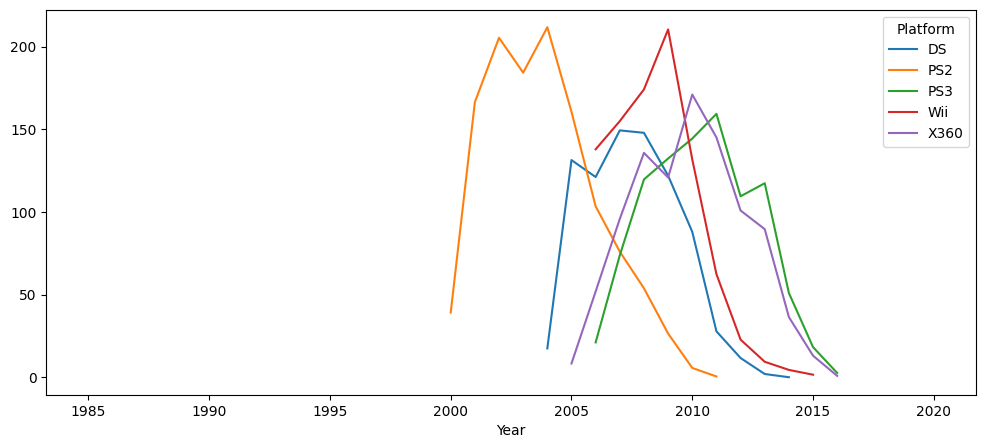

In [17]:
platform_trends = df[df['Platform'].isin(top_platforms)].groupby(['Year', 'Platform'])['Global_Sales'].sum().unstack()

platform_trends.plot(figsize=(12, 5))

For Question 3:

The PlayStation 2 (PS2) recorded the highest global sales, followed by Xbox 360, PS3, Wii and DS. Platform sales trends changed over time, reflecting the rise and decline in popularity of different gaming platforms.